# 03 – Exploratory analysis and RQ1

**RQ1:** How is pull request size (changed lines, changed files) associated with the amount of review activity, and does this relationship differ between AI-agent and human pull requests within the same repositories?

**Model.** Poisson pseudo-maximum-likelihood with repository and month fixed effects, standard errors clustered by repository:

$$E[y_i] = \exp(\beta_1 \log(1+\text{size}_i) + \beta_2\,\text{AI}_i + \beta_3 \log(1+\text{size}_i)\cdot\text{AI}_i + \alpha_{\text{repo}} + \gamma_{\text{month}})$$

* Repository fixed effects mean every comparison is made **within the same repository**.
* $\beta_1$ is the size **elasticity** for human PRs: 1% larger PR → about $\beta_1$% more review activity. For AI-agent PRs it is $\beta_1+\beta_3$.
* $\beta_3$ answers RQ1's second part: does the size–review relationship differ for AI-agent PRs?
* Poisson PML is consistent for overdispersed counts and has no incidental-parameter problem with many fixed effects (unlike negative binomial). A two-part (hurdle) model is a robustness check because most PRs get no review.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("ESS_DATA", ROOT / "data"))        # override only for testing
RESULTS = Path(os.environ.get("ESS_RESULTS", ROOT / "results"))
import pandas as pd
import analysis as an
import visualization as viz
viz.setup()
FIG, TAB = RESULTS / "figures", RESULTS / "tables"
TAB.mkdir(parents=True, exist_ok=True)
df = an.load(DATA / "processed/prs.parquet")
print(f"{len(df):,} PRs, {df.repo.nunique()} repositories")

306,512 PRs, 1248 repositories


## 1. Descriptive statistics

In [2]:
desc = an.describe(df)
desc.to_csv(TAB / "rq1_descriptives.csv")
desc

median            mean           share_zero       
author_kind           AI agent Human  AI agent     Human   AI agent  Human
variable                                                                  
files_changed              3.0   3.0    17.491    23.371      0.020  0.005
lines_changed            116.0  88.0  2436.842  3092.324      0.022  0.007
review_comments_total      0.0   0.0     1.521     2.101      0.722  0.629
reviewers_total            0.0   1.0     0.744     1.098      0.528  0.338
reviews_total              0.0   1.0     1.297     1.827      0.528  0.338

## 2. Distribution of PR size

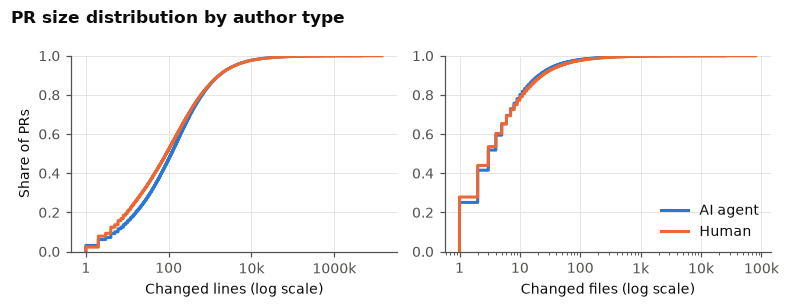

In [3]:
viz.size_ecdf(df, FIG);

## 3. Review activity by PR size

Mean per PR in each size decile (deciles of the pooled data), with 95% confidence bands. This is descriptive and pools repositories; the models in section 4 compare within repositories.

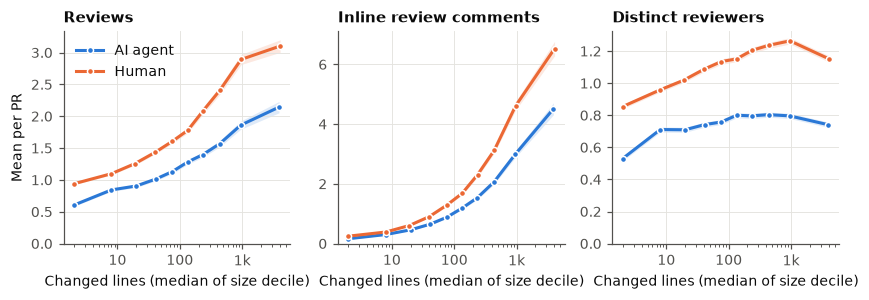

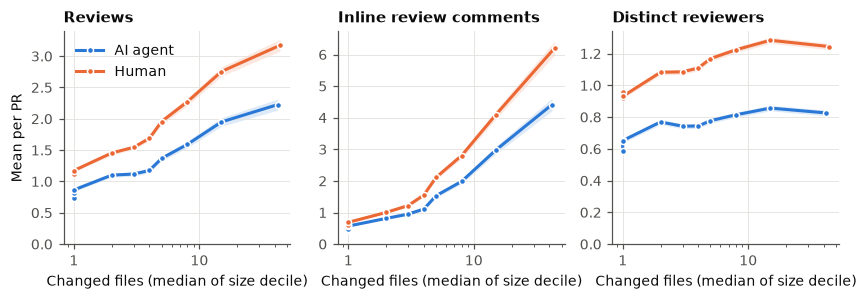

In [4]:
for col, label, name in [("lines_changed", "Changed lines", "fig_rq1_binned_lines"),
                         ("files_changed", "Changed files", "fig_rq1_binned_files")]:
    viz.binned_relationship({lab: an.binned_means(df, col, y) for y, lab in an.OUTCOMES.items()}, label, FIG, name)

## 4. Within-repository models (main RQ1 result)

One model per outcome × size measure. `elasticity` for *Human* is $\beta_1$, for *AI agent* $\beta_1+\beta_3$; the *Difference* row is $\beta_3$ with its p-value.

In [5]:
rq1 = an.rq1_table(df)
rq1.to_csv(TAB / "rq1_elasticities.csv", index=False)
rq1.round(3)

.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 17588 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 17588 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


,outcome,size,group,elasticity,se,ci_low,ci_high,p,n_used
0,Reviews,Changed lines (log),Human,0.165,0.004,0.156,0.174,0.000,296954
1,Reviews,Changed lines (log),AI agent,0.178,0.005,0.167,0.188,0.000,296954
2,Reviews,Changed lines (log),Difference (AI - Human),0.012,0.005,0.002,0.023,0.022,296954
3,Reviews,Changed files (log),Human,0.239,0.008,0.223,0.255,0.000,296954
4,Reviews,Changed files (log),AI agent,0.272,0.009,0.253,0.290,0.000,296954
5,Reviews,Changed files (log),Difference (AI - Human),0.033,0.009,0.014,0.051,0.001,296954
6,Inline review comments,Changed lines (log),Human,0.348,0.007,0.334,0.362,0.000,288923
7,Inline review comments,Changed lines (log),AI agent,0.354,0.007,0.340,0.368,0.000,288923
8,Inline review comments,Changed lines (log),Difference (AI - Human),0.006,0.008,-0.010,0.023,0.447,288923
9,Inline review comments,Changed files (log),Human,0.451,0.012,0.429,0.474,0.000,288923


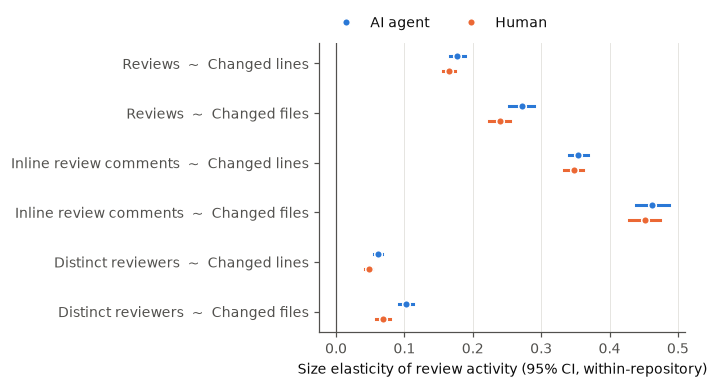

In [6]:
viz.elasticity_forest(rq1, FIG);

## 4b. How much review do agent PRs get compared with equally large human PRs?

The elasticities describe how fast review activity grows with size; the **rate ratio** compares the level. It is the expected review activity of an agent PR divided by that of a human PR of the same size in the same repository, $\exp(\beta_2 + \beta_3 \log(1+\text{size}))$, shown for PRs with 10, 100 and 1,000 changed lines. A value of 0.7 means 30% less review activity.

In [7]:
rr = an.rate_ratios(df)
rr.to_csv(TAB / "rq1_rate_ratios.csv", index=False)
rr.round(3)

.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 17588 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


,outcome,size,rate_ratio,ci_low,ci_high,p
0,Reviews,10,0.850,0.817,0.884,0.0
1,Reviews,100,0.874,0.845,0.903,0.0
2,Reviews,1000,0.899,0.861,0.938,0.0
3,Inline review comments,10,0.817,0.765,0.873,0.0
4,Inline review comments,100,0.829,0.792,0.867,0.0
5,Inline review comments,1000,0.841,0.800,0.883,0.0
6,Distinct reviewers,10,0.827,0.802,0.853,0.0
7,Distinct reviewers,100,0.851,0.830,0.873,0.0
8,Distinct reviewers,1000,0.877,0.854,0.901,0.0


## 5. Robustness: two-part (hurdle) model

(1) Logit: does the PR receive any review at all? (2) Poisson on PRs with at least one review: how much? If the size × AI interaction keeps its sign in both parts, the main result does not come only from the many zero-review PRs.

In [8]:
rows = []
for size in an.SIZE_MEASURES:
    p1, p2 = an.hurdle(df, "reviews_total", size)
    for part, fit in [("any review (logit)", p1), ("amount if > 0 (Poisson)", p2)]:
        t = fit.tidy().reset_index()
        t.insert(0, "part", part)
        t.insert(0, "size", an.SIZE_MEASURES[size])
        rows.append(t)
hurdle = pd.concat(rows, ignore_index=True)
hurdle.to_csv(TAB / "rq1_hurdle.csv", index=False)
hurdle.round(3)

.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 34 singleton fixed effect(s) dropped from the model.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 34 singleton fixed effect(s) dropped from the model.
  warnings.warn(


,size,part,Coefficient,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%
0,Changed lines (log),any review (logit),log_lines,0.067,0.009,7.430,0.000,0.049,0.085
1,Changed lines (log),any review (logit),ai,-0.901,0.069,-13.035,0.000,-1.037,-0.766
2,Changed lines (log),any review (logit),log_lines:ai,0.062,0.011,5.513,0.000,0.040,0.083
3,Changed lines (log),amount if > 0 (Poisson),log_lines,0.167,0.004,42.176,0.000,0.159,0.175
4,Changed lines (log),amount if > 0 (Poisson),ai,0.060,0.026,2.256,0.024,0.008,0.111
5,Changed lines (log),amount if > 0 (Poisson),log_lines:ai,-0.006,0.005,-1.297,0.195,-0.016,0.003
6,Changed files (log),any review (logit),log_files,0.080,0.017,4.804,0.000,0.047,0.112
7,Changed files (log),any review (logit),ai,-0.840,0.058,-14.442,0.000,-0.954,-0.726
8,Changed files (log),any review (logit),log_files:ai,0.140,0.021,6.640,0.000,0.099,0.182
9,Changed files (log),amount if > 0 (Poisson),log_files,0.249,0.008,32.090,0.000,0.233,0.264


## 6. How to read the results

* **Elasticity > 0:** larger PRs receive more review activity. Compare the size of the Human and AI-agent elasticities.
* **Difference (AI − Human) < 0 and significant:** review activity grows *less* with size for AI-agent PRs than for human PRs in the same repository; > 0 means it grows more.
* Results are associations, not causal effects (threats to validity: PR purpose, author experience, repository review policies over time).